# 07 - Comparación de las dos formas de elegir el modelo

El profesor nos marcó que lo más difícil del proyecto es **cómo dividir los datos**. Por eso comparamos dos formas de elegir el modelo. Las dos usan los mismos candidatos (las 10 regresiones Ridge del notebook 06 y 3 modelos de árboles con boosting), validan en **los mismos días** (todo 2025), se vuelven a entrenar con 2024 y 2025 y se prueban **una sola vez** en 2026.

| | **Opción 1: holdout de un año** | **Opción 2: validación cruzada temporal** |
|---|---|---|
| Cómo se valida 2025 | Un solo modelo entrenado con 2024 predice todo 2025 | 2025 se parte en 4 trimestres. Cada trimestre lo predice un modelo entrenado con **todo lo anterior** |
| Train de cada parte | Siempre 2024 | 2024 → 2024 + T1 → 2024 + T1 + T2 → 2024 + T1 + T2 + T3 |
| Cómo se elige | Menor MAE en 2025 | Menor MAE en 2025, juntando los 4 trimestres |
| Reentrenamiento final | 2024 + 2025 | 2024 + 2025 |
| Test | 2026, una vez | 2026, una vez |

El gráfico "Esquema de las dos opciones", más abajo, muestra lo mismo con las fechas: en azul con qué entrena cada modelo, en naranja qué parte de 2025 predice y en verde el test.

La ventana T1 de la opción 2 tiene el mismo train que la opción 1, así que en enero a marzo las dos tienen que dar exactamente lo mismo. La diferencia aparece de abril en adelante, cuando la opción 2 ya entrena con meses de 2025.

**Qué preguntamos:**
1. ¿Eligen el mismo modelo?
2. El modelo que elige cada una, ¿cuánto se equivoca en 2026?
3. ¿Cuál **anticipa mejor** el error de 2026? Si validación promete un error y en test sale mucho más alto, esa forma de validar es optimista.
4. ¿El orden de los candidatos en validación se mantiene en test?

**Este notebook no toca las tablas de los otros.** Solo lee `demanda_gold` y guarda sus resultados en otra tabla, `comparacion_validacion`. No vuelve a armar gold ni pisa `resultados_modelos`.

**De dónde venimos.** En el 06 elegimos la mejor regresión con train 2024 y val 2025. Ahí vimos que Ridge no sobreajusta y que los días que le cuestan (Turismo, la primera semana de enero, días únicos) piden combinar la línea, la hora y el tipo de día, cosa que una regresión no hace sola. Por eso acá sumamos árboles con boosting. La división del 06 es la opción 1, así que antes de comparar controlamos que las regresiones den lo mismo que allá (sección 3).

Las ventanas están en `config.OPCIONES_VALIDACION` y las funciones en `src/bondis/validacion.py`.

In [0]:
%run ./00_setup

# 00 - Preparar el proyecto

Este notebook deja todo listo para que los demás funcionen. Hace cuatro cosas:

1. Le dice a Python dónde está nuestro código (la carpeta `src/bondis`), para poder escribir `from bondis import ...`.
2. Crea en Databricks el lugar donde se guardan las tablas y los archivos (`bondis_stm.datos.raw`, definido en `config.py`).
3. Crea una carpeta para cada tipo de archivo (viajes, clima, etc.).
4. Muestra cómo dividimos los datos en train, val y test.

Se puede correr todas las veces que quieras. Si algo ya existe, no lo vuelve a crear ni lo borra.

No hace falta abrirlo a mano: los otros notebooks lo corren al principio con `%run ./00_setup`.

## 1. Encontrar nuestro código

Python solo puede importar código de las carpetas que conoce. Esta celda busca la carpeta del repositorio subiendo carpeta por carpeta hasta encontrar `src/bondis`, y la agrega a la lista de carpetas que Python conoce (`sys.path`).

Código encontrado en: Trabajo-Aprendizaje-Automatico-I/src


## 2. Crear el catálogo, el esquema y el volume

Databricks ordena todo en tres niveles, como carpetas una dentro de otra:

- **Catálogo** (`bondis_stm`): la carpeta grande del proyecto.
- **Esquema** (`datos`): una subcarpeta donde van las tablas.
- **Volume** (`raw`): una carpeta para guardar archivos sueltos, como los ZIP y CSV que bajamos.


Catálogo y esquema listos: bondis_stm.datos
Volume listo:  /Volumes/bondis_stm/datos/raw


## 3. Crear una carpeta para cada tipo de archivo

| Carpeta | Qué va adentro |
|---|---|
| `viajes_zip/` | Los ZIP de viajes de cada mes, bajados a mano del portal de la Intendencia |
| `viajes/` | Los CSV de viajes, ya sacados de los ZIP |
| `clima/` | Lluvia y temperatura de cada hora |

El calendario (feriados, clases y paros) no tiene carpeta, porque está escrito a mano en `src/bondis/calendario.py`.

Carpeta lista: /Volumes/bondis_stm/datos/raw/viajes_zip
Carpeta lista: /Volumes/bondis_stm/datos/raw/viajes
Carpeta lista: /Volumes/bondis_stm/datos/raw/clima


## 4. Revisar que todo esté bien

Muestra la versión de Spark y cuántos archivos hay en cada carpeta. Sirve para ver de un vistazo si falta subir algo.

Si este notebook lo llama otro con `%run`, solo muestra cuántos archivos hay en cada carpeta. La lista archivo por archivo y la tabla con las tablas del esquema aparecen solo cuando se corre el 00 solo. Así las salidas de los demás notebooks quedan cortas.

Versión de Spark: 4.2.0

/Volumes/bondis_stm/datos/raw/viajes_zip: 34 archivo(s), 10152.3 MB
/Volumes/bondis_stm/datos/raw/viajes: 34 archivo(s), 92981.1 MB
/Volumes/bondis_stm/datos/raw/clima: 2 archivo(s), 2.1 MB


## 5. Cómo dividimos los datos

Usamos las fechas para dividir, no el azar, porque queremos predecir el futuro con el pasado. Un año entero para cada cosa:

| Conjunto | Fechas | Para qué se usa |
|---|---|---|
| `train` | todo 2024 | El modelo aprende con estos datos |
| `val` | todo 2025 | Comparamos y elegimos los parámetros de la regresión |
| `test` | 2026 (lo que haya) | Probamos el modelo elegido una sola vez, al final |

La fecha de fin **no** está incluida. Por eso siempre se filtra con `fecha >= inicio` y `fecha < fin`.

`train_final` es train + val juntos. Cuando ya elegimos el modelo, lo volvemos a entrenar con 2024 y 2025 antes de probarlo en 2026.

Conjunto     Inicio       Fin (excl.) 
train        2024-01-01   2025-01-01  
val          2025-01-01   2026-01-01  
test         2026-01-01   2027-01-01  
train_final  2024-01-01   2026-01-01  

Horizonte de predicción: 1 día(s)
Semilla: 42


In [0]:
import importlib
from datetime import datetime

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

from bondis import calendario, metricas, modelos, validacion, variables

# calendario primero: modelos lo usa y reload(modelos) no lo vuelve a leer solo
for _m in (calendario, metricas, modelos, validacion, variables):
    importlib.reload(_m)

spark.conf.set("spark.sql.session.timeZone", config.TIMEZONE)
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

REFERENCIA = "mediana_4sem"
REGLAS = ["mediana_4sem", "perfil_historico", "regla_por_tipo_dia"]
# Árboles: poisson, log y residual (la que aprende cuánto corregir la mediana).
# Tardan bastante más que Ridge. Si Databricks no llega, poner False y se corre solo con Ridge.
INCLUIR_ARBOLES = True

CANDIDATOS = validacion.candidatos_ridge()   # los mismos 10 del notebook 06
if INCLUIR_ARBOLES:
    CANDIDATOS.update(validacion.candidatos_arboles())
OPCIONES = config.OPCIONES_VALIDACION

print("Candidatos:", list(CANDIDATOS))
for opcion, ventanas in OPCIONES.items():
    print(f"{opcion}: {[v[0] for v in ventanas]}")

Candidatos: ['lineal_aditivo_a1', 'lineal_aditivo_a1000', 'lineal_aditivo_a10000', 'lineal_aditivo_a100000', 'lineal_aditivo_a1000000', 'lineal_interacciones_a1', 'lineal_interacciones_a1000', 'lineal_interacciones_a10000', 'lineal_interacciones_a100000', 'lineal_interacciones_a1000000', 'hgb_poisson_h63', 'hgb_log_h63', 'hgb_residual_h63']
opcion_1: ['2025']
opcion_2: ['2025_T1', '2025_T2', '2025_T3', '2025_T4']


### Esquema de las dos opciones

Cada fila es un modelo. La opción 1 entrena una sola vez con 2024 y predice todo 2025. La opción 2 entrena cuatro veces, cada una con todo lo anterior, y predice un trimestre por vez. Al final las dos se vuelven a entrenar con 2024 y 2025 y se prueban en 2026. La fila "Opción 2: T1" tiene el mismo train que la opción 1, por eso en ese trimestre tienen que dar igual.

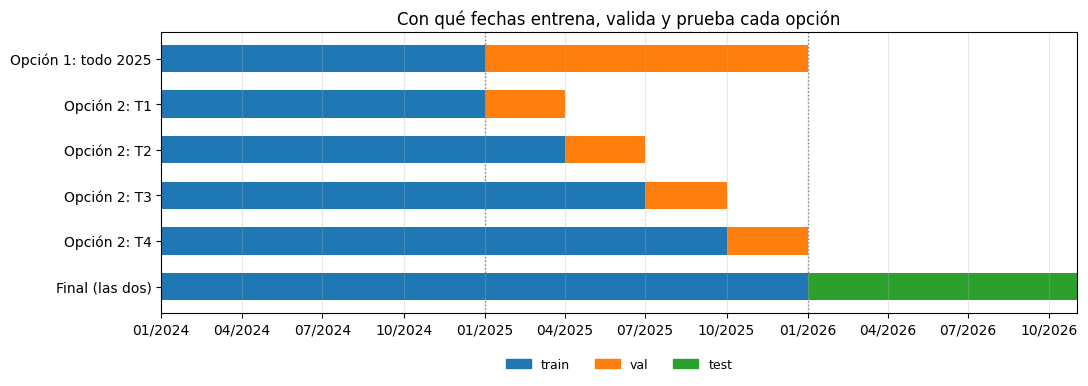

In [0]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch

# Esquema de las dos opciones: qué fechas usa cada modelo para entrenar, validar y probar
inicio = pd.Timestamp(config.FECHA_INICIO)
inicio_test = pd.Timestamp(config.FECHA_INICIO_TEST)
fin_test = pd.Timestamp("2026-11-01")   # los datos llegan hasta octubre de 2026
nombres = {"opcion_1": "Opción 1", "opcion_2": "Opción 2"}
colores = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

filas = []   # (etiqueta, desde, hasta, tipo): train va siempre desde el inicio hasta 'desde'
for opcion, ventanas in OPCIONES.items():
    for nombre, desde, hasta in ventanas:
        parte = "todo 2025" if len(ventanas) == 1 else nombre.split("_")[-1]
        filas.append((f"{nombres.get(opcion, opcion)}: {parte}", pd.Timestamp(desde), pd.Timestamp(hasta), "val"))
filas.append(("Final (las dos)", inicio_test, fin_test, "test"))

d = mdates.date2num
fig, ax = plt.subplots(figsize=(11, 4))
for y, (etiqueta, desde, hasta, tipo) in enumerate(reversed(filas)):
    ax.barh(y, d(desde) - d(inicio), left=d(inicio), height=0.6, color=colores["train"])
    ax.barh(y, d(hasta) - d(desde), left=d(desde), height=0.6, color=colores[tipo])
ax.set_yticks(range(len(filas)), [f[0] for f in reversed(filas)])
for anio in (2025, 2026):
    ax.axvline(d(pd.Timestamp(f"{anio}-01-01")), color="gray", ls=":", lw=1)
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_xlim(d(inicio), d(fin_test))
ax.legend(handles=[Patch(color=c, label=t) for t, c in colores.items()], loc="upper center",
          bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9, frameon=False)
ax.set_title("Con qué fechas entrena, valida y prueba cada opción")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 1. Datos

Se bajan a pandas las filas completas de 2024 y 2025 (lo que se usa para elegir el modelo). **2026 no se baja todavía**, recién en la sección 5.

El tamaño de cada línea (grande, mediana, chica) se calcula con 2024, igual que en el 06, para que los cortes por tamaño sean los mismos en las dos opciones.

In [0]:
gold = variables.con_tipo_dia(spark.table(config.TABLE_GOLD)).where(F.col("fila_completa"))
primer_dia_val = gold.where(F.col("particion") == "val").agg(F.min("fecha")).first()[0]
assert primer_dia_val is not None and primer_dia_val.year == 2025, \
    "Gold no tiene val en 2025. Hay que volver a correr el notebook 03."

leer, faltantes = modelos.columnas_a_leer(gold.columns)
if faltantes:
    print("Columnas opcionales que gold todavía no tiene (se sigue sin ellas):", faltantes)

tamanos = variables.tamano_linea(gold.where(F.col("particion") == "train")).toPandas()


def bajar(desde, hasta):
    # Filas completas desde 'desde' hasta 'hasta' (sin incluirlo), en pandas, con el tamaño de la línea.
    df = (gold.where((F.col("fecha") >= F.to_date(F.lit(desde))) & (F.col("fecha") < F.to_date(F.lit(hasta))))
          .select(*leer).toPandas()
          .merge(tamanos, on="linea", how="left")
          .fillna({"tamano_linea": "chica"}))
    df["fecha"] = pd.to_datetime(df["fecha"])
    # Spark no devuelve las filas siempre en el mismo orden. Las ordenamos para que los resultados
    # den igual en cada corrida (los árboles y algunas muestras dependen del orden de las filas).
    return df.sort_values(["linea", "fecha", "hora"]).reset_index(drop=True)


datos = bajar(config.FECHA_INICIO, config.FECHA_INICIO_TEST)
print(f"2024 y 2025: {len(datos):,} filas, {datos['fecha'].nunique()} días "
      f"({datos['fecha'].min().date()} a {datos['fecha'].max().date()}), {datos['linea'].nunique()} líneas")

2024 y 2025: 2,291,568 filas, 703 días (2024-01-29 a 2025-12-31), 136 líneas


## 2. Entrenar y predecir 2025 con cada opción

Para cada ventana: se entrenan todos los candidatos con su train, se predice su parte de 2025 y se calculan las reglas simples con las mismas filas. Las líneas y tipos de día que conoce cada modelo salen solo de su train.

La opción 1 entrena cada candidato una vez y la opción 2 cuatro veces (una por trimestre). Las regresiones tardan segundos. Los árboles tardan bastante más (pueden ser uno o dos minutos cada uno), así que con árboles esta celda puede llevar media hora o más.

En la opción 2 cada trimestre entrena con más filas que el anterior, pero el `alfa` de cada regresión queda fijo. Eso importa porque Ridge compara el castigo contra la suma de los errores de todas las filas (ver 06, sección 6.2), así que con más filas el mismo `alfa` castiga menos. Para los `alfa` grandes la opción 2 va a salir mejor solo por eso, no porque los datos de 2025 ayuden.

In [0]:
est_val, detalle = {}, {}
for opcion, ventanas in OPCIONES.items():
    print(f"=== {opcion}")
    est_val[opcion], detalle[opcion] = validacion.evaluar_opcion(datos, ventanas, CANDIDATOS, config.FECHA_INICIO)
    print()

print(pd.concat([d.assign(opcion=o) for o, d in detalle.items()]).to_string(index=False))

=== opcion_1
[2025] train 2024-01-29 a 2024-12-31 (1,100,208 filas) -> val 2025-01-01 a 2025-12-31 (1,191,360 filas), 230.3 s

=== opcion_2
[2025_T1] train 2024-01-29 a 2024-12-31 (1,100,208 filas) -> val 2025-01-01 a 2025-03-31 (293,760 filas), 184.0 s
[2025_T2] train 2024-01-29 a 2025-03-31 (1,393,968 filas) -> val 2025-04-01 a 2025-06-30 (297,024 filas), 215.1 s
[2025_T3] train 2024-01-29 a 2025-06-30 (1,690,992 filas) -> val 2025-07-01 a 2025-09-30 (300,288 filas), 260.5 s
[2025_T4] train 2024-01-29 a 2025-09-30 (1,991,280 filas) -> val 2025-10-01 a 2025-12-31 (300,288 filas), 315.1 s

ventana train_desde train_hasta  dias_train  filas_train  val_desde  val_hasta  dias_val  filas_val  segundos   opcion
   2025  2024-01-29  2024-12-31         338      1100208 2025-01-01 2025-12-31       365    1191360     230.3 opcion_1
2025_T1  2024-01-29  2024-12-31         338      1100208 2025-01-01 2025-03-31        90     293760     184.0 opcion_2
2025_T2  2024-01-29  2025-03-31         428   

**Control.** Las dos opciones tienen que predecir exactamente las mismas filas y días. Además, en el primer trimestre (mismo train) tienen que dar el mismo error.

In [0]:
filas = {o: int(e.loc[e["modelo"] == REFERENCIA, "n"].sum()) for o, e in est_val.items()}
dias = {o: e["fecha"].nunique() for o, e in est_val.items()}
print("Filas de validación:", filas)
print("Días de validación: ", dias)
assert len(set(filas.values())) == 1 and len(set(dias.values())) == 1, "Las opciones no validan las mismas filas"


def error_t1(e):
    t1 = e[validacion.trimestre(e["fecha"]) == "2025_T1"]
    return t1[t1["modelo"].isin(CANDIDATOS)].groupby("modelo")["s_abs"].sum()


dif_t1 = (error_t1(est_val["opcion_1"]) - error_t1(est_val["opcion_2"])).abs().max()
print(f"Diferencia máxima en el primer trimestre: {dif_t1:.6f} (tiene que ser 0)")

Filas de validación: {'opcion_1': 1191360, 'opcion_2': 1191360}
Días de validación:  {'opcion_1': 365, 'opcion_2': 365}
Diferencia máxima en el primer trimestre: 0.000000 (tiene que ser 0)


## 3. Resultados en validación (2025)

Igual que en el 05 y el 06: el MAE con su intervalo del 95 % (sorteando semanas) y la mejora sobre la mediana de 4 semanas.

La opción 1 tendría que elegir el mismo modelo que el notebook 06, porque es la misma división con las mismas filas.

In [0]:
resumen_val = {o: validacion.resumen(e, REFERENCIA, n_rep=1000, seed=config.SEED) for o, e in est_val.items()}
elegidos = {o: validacion.elegir(r, CANDIDATOS) for o, r in resumen_val.items()}

for o, r in resumen_val.items():
    print(f"=== {o}: elige {elegidos[o]}")
    print(validacion.para_mostrar(r).to_string(index=False))
    print()

if len(set(elegidos.values())) == 1:
    print("Las dos opciones eligen el mismo modelo.")
else:
    print("Las opciones eligen modelos distintos:", elegidos)

=== opcion_1: elige hgb_poisson_h63
                       modelo         MAE [IC 95 %]  RMSE   WAPE  sesgo               mejora [IC 95 %]
              hgb_poisson_h63    26.6 [24.9 a 28.7]  55.8 10.6 %    4.2       33.0 % [26.0 % a 40.4 %]
                  hgb_log_h63    27.0 [25.3 a 29.0]  57.2 10.8 %    1.0       32.0 % [24.9 % a 39.4 %]
             hgb_residual_h63    27.3 [25.2 a 30.0]  57.8 10.9 %    3.6       31.2 % [24.6 % a 37.9 %]
   lineal_interacciones_a1000    30.6 [28.5 a 33.1]  64.7 12.2 %   -3.9       23.1 % [16.1 % a 30.3 %]
      lineal_interacciones_a1    30.7 [28.6 a 33.4]  65.5 12.3 %   -3.1       22.7 % [15.8 % a 30.2 %]
         lineal_aditivo_a1000    30.8 [28.8 a 33.3]  65.0 12.3 %   -4.9       22.4 % [15.4 % a 29.4 %]
  lineal_interacciones_a10000    30.9 [29.1 a 33.0]  64.8 12.3 %   -6.2       22.3 % [15.5 % a 29.8 %]
            lineal_aditivo_a1    30.9 [28.8 a 33.4]  65.2 12.3 %   -4.6       22.3 % [15.2 % a 29.4 %]
        lineal_aditivo_a10000    31.1

**Control contra el 06.** La opción 1 es la misma división que el 06, con las mismas filas y los mismos candidatos de Ridge. Leemos lo que guardó el 06 en `resultados_modelos` y comparamos. Si la diferencia no es casi 0, algo cambió entre las dos corridas (gold, el código o las variables) y hay que volver a correr el 06.

In [0]:
if spark.catalog.tableExists(config.TABLE_RESULTADOS):
    del_06 = (spark.table(config.TABLE_RESULTADOS).where(F.col("etapa") == "modelo")
              .select("modelo", "mae", "seleccionado").toPandas().set_index("modelo"))
    control = del_06[["mae"]].rename(columns={"mae": "mae_06"}).join(
        resumen_val["opcion_1"].set_index("modelo")["mae"].rename("mae_07_opcion_1"), how="inner")
    control["diferencia"] = control["mae_07_opcion_1"] - control["mae_06"]
    print(control.round(3).to_string())
    print(f"\nDiferencia máxima: {control['diferencia'].abs().max():.4f}")
    print("Elegida en el 06:", ", ".join(del_06.index[del_06["seleccionado"]]))
else:
    print("Todavía no está la tabla del 06. Correr el 06 antes para poder comparar.")

                                mae_06  mae_07_opcion_1  diferencia
modelo                                                             
lineal_interacciones_a1000      30.569           30.569         0.0
lineal_interacciones_a1         30.700           30.700         0.0
lineal_aditivo_a1000            30.815           30.815         0.0
lineal_interacciones_a10000     30.852           30.852         0.0
lineal_aditivo_a1               30.866           30.866         0.0
lineal_aditivo_a10000           31.113           31.113         0.0
regla_por_tipo_dia              34.819           34.819         0.0
lineal_interacciones_a100000    36.964           36.964         0.0
lineal_aditivo_a100000          37.270           37.270         0.0
perfil_historico                37.560           37.560         0.0
mediana_4sem                    39.730           39.730         0.0
lineal_interacciones_a1000000  104.636          104.636         0.0
lineal_aditivo_a1000000        104.959          

### 3.1 Los candidatos lado a lado

El MAE y el puesto de cada candidato en las dos opciones. Si los puestos cambian mucho, la forma de validar cambia la decisión.

In [0]:
lado = pd.concat({o: r.set_index("modelo")[["mae", "mejora_mae"]] for o, r in resumen_val.items()}, axis=1)
lado = lado.loc[[*CANDIDATOS, *REGLAS]]
for o in OPCIONES:
    lado[(o, "puesto")] = lado.loc[list(CANDIDATOS), (o, "mae")].rank(method="min")
lado = lado[[(o, c) for o in OPCIONES for c in ("mae", "mejora_mae", "puesto")]]
print(lado.round(3).to_string())

                              opcion_1                   opcion_2                  
                                   mae mejora_mae puesto      mae mejora_mae puesto
modelo                                                                             
lineal_aditivo_a1               30.866      0.223    8.0   32.028      0.194    8.0
lineal_aditivo_a1000            30.815      0.224    6.0   31.979      0.195    7.0
lineal_aditivo_a10000           31.113      0.217    9.0   32.122      0.191    9.0
lineal_aditivo_a100000          37.270      0.062   11.0   36.420      0.083   11.0
lineal_aditivo_a1000000        104.959     -1.642   13.0   89.433     -1.251   13.0
lineal_interacciones_a1         30.700      0.227    5.0   31.531      0.206    5.0
lineal_interacciones_a1000      30.569      0.231    4.0   31.439      0.209    4.0
lineal_interacciones_a10000     30.852      0.223    7.0   31.735      0.201    6.0
lineal_interacciones_a100000    36.964      0.070   10.0   36.115      0.091

### 3.1.1 Ridge contra árboles

El mejor de cada tipo de modelo en cada opción. Sirve para ver si la diferencia entre opciones está en elegir entre tipos de modelo o en ajustar los parámetros dentro de un tipo. Abajo de cada tabla está cuánto le gana el mejor árbol a la mejor Ridge, con el mismo bootstrap por semanas. Si el intervalo no incluye el 0, la diferencia no es por los días que tocaron.

In [0]:
def tipo_modelo(nombre):
    return "ridge" if nombre.startswith("lineal") else "árboles"


for o, r in resumen_val.items():
    c = r[r["modelo"].isin(CANDIDATOS)].assign(tipo=lambda t: t["modelo"].map(tipo_modelo))
    mejores = c.loc[c.groupby("tipo")["mae"].idxmin(), ["tipo", "modelo", "mae", "mejora_mae", "mejora_mae_inf", "mejora_mae_sup"]]
    print(f"{o}:")
    print(mejores.round(3).to_string(index=False))
    m = mejores.set_index("tipo")["modelo"]
    if len(m) == 2:   # solo si se corrieron los árboles
        d = validacion.diferencia_entre_opciones(est_val[o], m["árboles"], m["ridge"], n_rep=1000, seed=config.SEED)
        print(f"Mejora de {m['árboles']} sobre {m['ridge']}: {100 * d['mejora']:.1f} % "
              f"[IC 95 %: {100 * d['inf']:.1f} % a {100 * d['sup']:.1f} %]")
    print()

opcion_1:
   tipo                     modelo    mae  mejora_mae  mejora_mae_inf  mejora_mae_sup
  ridge lineal_interacciones_a1000 30.569       0.231           0.161           0.303
árboles            hgb_poisson_h63 26.607       0.330           0.260           0.404
Mejora de hgb_poisson_h63 sobre lineal_interacciones_a1000: 13.0 % [IC 95 %: 10.1 % a 15.7 %]

opcion_2:
   tipo                     modelo    mae  mejora_mae  mejora_mae_inf  mejora_mae_sup
  ridge lineal_interacciones_a1000 31.439       0.209           0.136           0.281
árboles            hgb_poisson_h63 26.477       0.334           0.264           0.404
Mejora de hgb_poisson_h63 sobre lineal_interacciones_a1000: 15.8 % [IC 95 %: 12.7 % a 18.7 %]



### 3.1.2 Contra la mejor regla simple

En el 05 la mediana de 4 semanas no fue la mejor regla simple. Para no agrandar lo que aporta el modelo, medimos también cuánto le gana el elegido a la mejor regla de validación, con el mismo bootstrap por semanas.

In [0]:
for o, r in resumen_val.items():
    mejor_regla = r[r["modelo"].isin(REGLAS)].sort_values("mae")["modelo"].iloc[0]
    d = validacion.diferencia_entre_opciones(est_val[o], elegidos[o], mejor_regla, n_rep=1000, seed=config.SEED)
    print(f"{o}: {elegidos[o]} contra {mejor_regla} (la mejor regla simple en validación): "
          f"{100 * d['mejora']:.1f} % menos error [IC 95 %: {100 * d['inf']:.1f} % a {100 * d['sup']:.1f} %]")

opcion_1: hgb_poisson_h63 contra regla_por_tipo_dia (la mejor regla simple en validación): 23.6 % menos error [IC 95 %: 18.5 % a 28.7 %]
opcion_2: hgb_poisson_h63 contra regla_por_tipo_dia (la mejor regla simple en validación): 24.0 % menos error [IC 95 %: 19.3 % a 28.9 %]


### 3.2 Trimestre por trimestre

La diferencia entre las opciones está en con qué datos se entrena cada trimestre. La tabla muestra, para cada candidato, el MAE de la opción 2 menos el de la opción 1 en cada trimestre. Negativo quiere decir que entrenar con los meses de 2025 ya pasados ayudó.

T1 tiene que dar 0. Lo que esperábamos ver es que la diferencia crezca hacia T4, porque ahí la opción 1 predice con datos de hasta un año atrás.

En el gráfico no van los candidatos que no le ganan a la mediana en ninguna de las dos opciones (los `alfa` más grandes), porque su diferencia es tan grande que aplasta a los demás. En la tabla sí están todos.

MAE por trimestre, opcion_1:
trimestre        2025_T1  2025_T2  2025_T3  2025_T4
modelo                                             
mediana_4sem       45.99    40.89    37.06    35.13
hgb_poisson_h63    31.63    24.58    25.60    24.70 

MAE por trimestre, opcion_2:
trimestre        2025_T1  2025_T2  2025_T3  2025_T4
modelo                                             
mediana_4sem       45.99    40.89    37.06    35.13
hgb_poisson_h63    31.63    24.01    25.69    24.66 

MAE opción 2 menos MAE opción 1 (negativo: la opción 2 se equivoca menos):
trimestre                      2025_T1  2025_T2  2025_T3  2025_T4
modelo                                                           
lineal_aditivo_a1                  0.0     0.61     2.39     1.62
lineal_aditivo_a1000               0.0     0.60     2.43     1.60
lineal_aditivo_a10000              0.0     0.52     2.18     1.30
lineal_aditivo_a100000             0.0    -0.95    -1.02    -1.42
lineal_aditivo_a1000000            0.0   -12.06   -

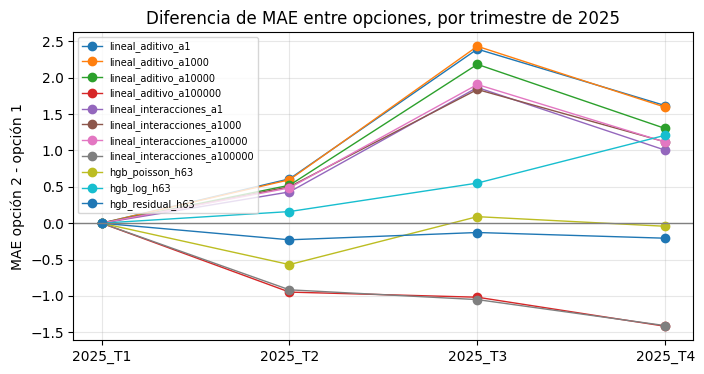

In [0]:
por_trim = {}
for o, e in est_val.items():
    m = metricas.metricas(e.assign(trimestre=validacion.trimestre(e["fecha"])), por=["trimestre"])
    por_trim[o] = m.pivot(index="modelo", columns="trimestre", values="mae")

mostrar = list(dict.fromkeys([REFERENCIA, *elegidos.values()]))
for o, t in por_trim.items():
    print(f"MAE por trimestre, {o}:")
    print(t.loc[mostrar].round(2).to_string(), "\n")

dif = (por_trim["opcion_2"] - por_trim["opcion_1"]).loc[list(CANDIDATOS)]
print("MAE opción 2 menos MAE opción 1 (negativo: la opción 2 se equivoca menos):")
print(dif.round(2).to_string())

utiles = [n for n in CANDIDATOS if max(r.set_index("modelo").loc[n, "mejora_mae"] for r in resumen_val.values()) > 0]
fig, ax = plt.subplots(figsize=(8, 4))
for nombre in utiles:
    ax.plot(dif.columns, dif.loc[nombre], marker="o", lw=1, label=nombre)
ax.axhline(0, color="gray", lw=1)
ax.set(title="Diferencia de MAE entre opciones, por trimestre de 2025", ylabel="MAE opción 2 - opción 1")
ax.legend(fontsize=7)
plt.show()

### 3.3 Por tipo de día

Los modelos elegidos y la referencia, separando por tipo de día.

In [0]:
for o, e in est_val.items():
    m = metricas.metricas(e[e["modelo"].isin(mostrar)], por=["tipo_dia"])
    tipos = [t for t in variables.TIPOS_DIA if t in set(m["tipo_dia"])]
    print(f"MAE por tipo de día, {o}:")
    print(m.pivot(index="modelo", columns="tipo_dia", values="mae").loc[mostrar, tipos].round(1).to_string(), "\n")

MAE por tipo de día, opcion_1:
tipo_dia         hábil  sábado  domingo  turismo  feriado
modelo                                                   
mediana_4sem      38.5    25.2     21.6    122.9    211.6
hgb_poisson_h63   28.9    22.4     19.0     30.9     26.3 

MAE por tipo de día, opcion_2:
tipo_dia         hábil  sábado  domingo  turismo  feriado
modelo                                                   
mediana_4sem      38.5    25.2     21.6    122.9    211.6
hgb_poisson_h63   28.9    22.5     18.6     27.4     25.1 



**Qué vimos en la sección 3.**
- **Las dos opciones eligen el mismo modelo**, `hgb_poisson_h63` (MAE 26,6 en las dos), y los puestos casi no cambian. Los tres árboles quedan en el mismo orden, y entre las regresiones solo se dan vuelta dos que están a menos de una décima. Para este problema la forma de validar no cambió la decisión.
- **Los árboles le ganan a todas las regresiones.** El mejor árbol se equivoca un 13,1 % menos que la mejor Ridge en la opción 1 (intervalo de 10,2 % a 16,0 %) y un 15,5 % menos en la opción 2. Como el intervalo no incluye el 0, la diferencia no es por los días que tocaron. Por tipo de día, el árbol mejora a la Ridge del 06 sobre todo en hábiles (29,0 contra 33,1) y en Turismo (27,4 contra 52,0), justo donde la regresión no podía combinar variables.
- **Entrenar con los meses de 2025 ya pasados no ayudó.** En las regresiones útiles (`alfa` de 1 a 10.000) la opción 2 se equivoca entre 0,4 y 2,4 pasajeros por hora más de T2 a T4. En los árboles `poisson` y `residual` la diferencia queda entre -0,3 y +0,3, que es ruido, y `hgb_log_h63` empeora un poco hacia T4 (+1,0).
- **Las regresiones con `alfa` de 100.000 y 1.000.000 mejoran con la opción 2**, cada vez más hacia T4. No es por los datos nuevos, sino porque con más filas el mismo `alfa` castiga menos (sección 2).
- **Por qué los datos nuevos no ayudan.** El nivel de cada línea ya entra por los rezagos, así que el modelo se adapta solo si cambia la cantidad de pasajeros. Lo que aprende de train es la forma (cómo pesan la hora, el tipo de día, los feriados), y eso casi no cambió de 2024 a 2025. Que a Ridge hasta le vaya peor no lo pudimos explicar. Pasaba igual antes de la mediana limpia, así que no venía de ahí.

### 3.4 Guardar los resultados de validación

Van a la tabla `comparacion_validacion` con `etapa = 'validacion'`, una fila por opción y modelo. `seleccionado` marca el que eligió cada opción. Si se vuelve a correr, se reemplazan solo esas filas.

In [0]:
COLUMNAS = ["modelo", "filas", "mae", "mae_inf", "mae_sup", "rmse", "rmse_inf", "rmse_sup", "r2", "wape",
            "sesgo", "mejora_mae", "mejora_mae_inf", "mejora_mae_sup"]


def para_guardar(tabla, etapa, opcion, elegido):
    s = tabla[COLUMNAS].copy()
    s = s.astype({c: "float64" for c in COLUMNAS if c not in ("modelo", "filas")}).astype({"filas": "int64"})
    s.insert(0, "opcion", opcion)
    s.insert(0, "etapa", etapa)
    s["referencia"] = REFERENCIA
    s["seleccionado"] = (s["modelo"] == elegido).to_numpy()
    s["fecha_ejecucion"] = datetime.now().strftime("%Y-%m-%d %H:%M")
    return s


def guardar(partes, etapa):
    df = pd.concat(partes, ignore_index=True)
    escritor = spark.createDataFrame(df).write.format("delta").mode("overwrite").option("mergeSchema", "true")
    if spark.catalog.tableExists(config.TABLE_COMPARACION):
        escritor = escritor.option("replaceWhere", f"etapa = '{etapa}'")
    escritor.saveAsTable(config.TABLE_COMPARACION)
    print(f"Guardado en {config.TABLE_COMPARACION} (etapa '{etapa}'): {len(df)} filas")


guardar([para_guardar(r, "validacion", o, elegidos[o]) for o, r in resumen_val.items()], "validacion")

Guardado en bondis_stm.datos.comparacion_validacion (etapa 'validacion'): 32 filas


## 4. Antes de mirar test

Anotar acá, **antes** de prender el test, qué eligió cada opción y qué error prometió validación. Después de mirar test no se cambia nada: ni candidatos, ni ventanas, ni variables.

| | Opción 1 | Opción 2 |
|---|---|---|
| Modelo elegido | `hgb_poisson_h63` | `hgb_poisson_h63` |
| MAE en validación | 26,6 [24,8 a 28,7] | 26,6 [24,8 a 28,7] |
| Mejora sobre la mediana en validación | 33,2 % [26,0 % a 40,3 %] | 33,2 % [26,1 % a 40,0 %] |
| Mejora sobre la mejor regla (`regla_por_tipo_dia`) en validación | 23,7 % [18,7 % a 28,9 %] | 23,8 % [19,1 % a 28,7 %] |

Las dos eligen el mismo modelo, así que en test van a tener el mismo error. Además el elegido saca casi el mismo MAE de validación en las dos, así que el `optimismo` también va a dar casi igual.

Los números de la tabla son de una corrida anterior. Entre corridas se movían unas centésimas (por ejemplo 26,55 y 26,57), porque Spark no devuelve las filas siempre en el mismo orden. Ahora las filas se ordenan al bajarlas (sección 1), así que los números ya no cambian de una corrida a otra. Los definitivos son los de la sección 3 de la corrida en la que se prende el test. La elección es la misma en todas las corridas, y eso es lo que controla el candado del test. Lo que sí puede separarlas es cómo anticipan el error de los 13 candidatos, porque las regresiones cambian bastante de una opción a la otra (30,6 contra 31,4 la mejor). Eso, y lo demás que vamos a mirar, está en la 4.1.

### 4.1 Lo que vamos a mirar en test (decidido antes de verlo)

Si las dos opciones eligen el mismo modelo, en test van a tener el mismo error. Y como en validación ese modelo saca casi el mismo MAE en las dos, el `optimismo` también va a dar casi igual. Con esas medidas solas la comparación sale empatada sí o sí, aunque una opción sea mejor que la otra.

Por eso, antes de prender el test, sumamos cuatro cosas (sección 5.1):

1. **Contra la mejor regla simple.** Medimos cuánto le gana el modelo elegido a la mejor regla de validación, no solo a la mediana.
2. **El error de todos los candidatos, no solo del elegido.** Validación le "promete" un error a cada uno de los 13 candidatos. En test vemos cuánto sacó de verdad cada uno. La opción cuyas promesas se acercan más a lo que pasó es la que adivina mejor. Lo miramos de dos formas. Con los 13, y con los 9 que en validación le ganan a la mediana con un intervalo que no toca el 0 en las dos opciones: las seis Ridge con `alfa` de 1 a 10.000 y los tres árboles. La segunda es la principal. Deja afuera las Ridge con `alfa` de 100.000 y 1.000.000, que en la opción 2 mejoran solo porque con más filas el mismo `alfa` castiga menos (sección 2), y que con MAE cercanos a 105 pesarían demasiado en `diferencia_promedio`. Por eso la medida principal es `diferencia_pct` con los 9.
3. **Los mismos meses.** Test llega hasta octubre de 2026 y validación es todo 2025. Repetimos la comparación usando solo los meses de 2025 que también tiene el test, para que noviembre y diciembre (fin de clases y fiestas) no ensucien la cuenta.
4. **Sin los días de paro.** Si un paro de 2026 se marca o no depende de cómo lo contaron las noticias (ver `calendario.py`). Sacamos del test todos los días con algún paro y miramos si la conclusión cambia.

Nada de esto cambia el modelo elegido. La elección sale solo de la sección 3.

La celda del test arranca con un candado: si la elección o el MAE de validación del elegido no coinciden con lo anotado en la sección 4 (por ejemplo, porque gold se rehízo o se reinició el cluster), frena antes de mirar 2026.

## 5. Test (2026): se corre UNA sola vez

1. Se entrenan todos los candidatos con **2024 y 2025** y se predice 2026. Como las dos opciones se reentrenan con los mismos datos, el modelo final de cada candidato es el mismo para las dos. Lo único que cambia entre opciones es **cuál** candidato eligieron.
2. Se calculan las reglas simples con las mismas filas.
3. Se compara lo que eligió cada opción.

Se predicen todos los candidatos (no solo los 2 elegidos) para poder ver si el orden de validación se mantiene en test. Eso es un **análisis posterior**: la elección ya quedó congelada en la sección 3 y no se cambia por lo que salga acá.

El test está apagado. Cuando estemos conformes con la sección 3, poner `EVALUAR_EN_TEST = True` y correr esta celda **una sola vez**.

In [0]:
EVALUAR_EN_TEST = True

if not EVALUAR_EN_TEST:
    print("Test apagado. Poner EVALUAR_EN_TEST = True cuando la sección 3 esté cerrada.")
else:
    # Candado: el test solo corre si la elección es la misma que anotamos en la sección 4.
    # Si gold cambió o se reinició el cluster y la validación dio otra cosa, frena acá, antes de mirar 2026.
    assert elegidos == {"opcion_1": "hgb_poisson_h63", "opcion_2": "hgb_poisson_h63"}, \
        f"La elección no coincide con la anotada en la sección 4: {elegidos}"
    # Antes de ordenar las filas el MAE se movía unas centésimas entre corridas (26,55 y 26,57).
    # Con 0,1 de margen eso no frena, pero un cambio real en gold o en el código sí.
    for _o, _anotado in (("opcion_1", 26.56), ("opcion_2", 26.55)):
        _mae = resumen_val[_o].set_index("modelo").loc["hgb_poisson_h63", "mae"]
        assert abs(_mae - _anotado) < 0.1, f"El MAE de validación de {_o} cambió: {_mae:.3f} (anotado {_anotado})"

    test_raw = bajar(config.FECHA_INICIO_TEST, config.FECHA_FIN)
    meses = sorted(test_raw["fecha"].dt.strftime("%Y-%m").unique())
    print(f"Test: {len(test_raw):,} filas, {test_raw['fecha'].nunique()} días, meses {meses[0]} a {meses[-1]}")

    est_test, segundos = validacion.entrenar_y_medir(datos, test_raw, CANDIDATOS)
    resumen_test = validacion.resumen(est_test, REFERENCIA, n_rep=1000, seed=config.SEED)
    print("\nTodos los candidatos y las reglas en test:")
    print(validacion.para_mostrar(resumen_test).to_string(index=False))

    comparacion = validacion.tabla_comparacion(resumen_val, resumen_test, elegidos, REFERENCIA)
    print("\nComparación de las dos opciones:")
    print(comparacion.set_index("opcion").T.round(3).to_string())

    print("\n¿El orden de validación se mantiene en test?")
    for o in OPCIONES:
        rho, orden = validacion.concordancia(resumen_val[o], resumen_test, CANDIDATOS)
        print(f"\n{o}: correlación de Spearman entre puestos de val y de test = {rho:.2f}")
        print(orden.round(2).to_string(index=False))

    d = validacion.diferencia_entre_opciones(est_test, elegidos["opcion_2"], elegidos["opcion_1"],
                                             n_rep=1000, seed=config.SEED)
    print(f"\nMejora en test del modelo de la opción 2 sobre el de la opción 1: {100 * d['mejora']:.1f} % "
          f"[IC 95 %: {100 * d['inf']:.1f} % a {100 * d['sup']:.1f} %]. "
          "Positivo: la opción 2 se equivoca menos. Si el intervalo incluye el 0, no hay diferencia clara.")

    mostrar_test = list(dict.fromkeys([REFERENCIA, *elegidos.values()]))
    m = metricas.metricas(est_test[est_test["modelo"].isin(mostrar_test)], por=["tipo_dia"])
    tipos = [t for t in variables.TIPOS_DIA if t in set(m["tipo_dia"])]
    print("\nMAE por tipo de día en test:")
    print(m.pivot(index="modelo", columns="tipo_dia", values="mae").loc[mostrar_test, tipos].round(1).to_string())

    guardar([para_guardar(resumen_test, "test", o, elegidos[o]) for o in OPCIONES], "test")

Test: 992,256 filas, 304 días, meses 2026-01 a 2026-10

Todos los candidatos y las reglas en test:
                       modelo      MAE [IC 95 %]  RMSE   WAPE  sesgo             mejora [IC 95 %]
              hgb_poisson_h63 24.1 [23.0 a 25.6]  51.8 10.0 %   -0.1     36.4 % [28.3 % a 44.0 %]
             hgb_residual_h63 24.5 [23.2 a 25.9]  54.5 10.1 %    0.4     35.5 % [27.5 % a 42.9 %]
                  hgb_log_h63 25.1 [23.9 a 26.5]  54.1 10.4 %   -3.3     33.9 % [25.4 % a 42.3 %]
      lineal_interacciones_a1 29.4 [27.1 a 31.9]  63.5 12.2 %   -7.0     22.5 % [14.8 % a 29.0 %]
   lineal_interacciones_a1000 29.4 [27.3 a 31.8]  63.2 12.2 %   -7.3     22.5 % [14.4 % a 29.2 %]
  lineal_interacciones_a10000 29.8 [27.8 a 32.1]  63.7 12.3 %   -8.4     21.5 % [13.0 % a 28.6 %]
            lineal_aditivo_a1 30.0 [28.0 a 32.3]  64.1 12.4 %   -8.7     20.8 % [12.4 % a 28.0 %]
         lineal_aditivo_a1000 30.0 [28.0 a 32.3]  64.2 12.4 %   -8.7     20.8 % [12.3 % a 27.9 %]
        lineal_adit

**Cómo leer la comparación.**
- `mae_val` y `mae_test`: el error del modelo elegido en 2025 y en 2026.
- `test/val`: cuánto creció el error al pasar de validación a test.
- `optimismo`: ese crecimiento dividido el de la mediana de 4 semanas. La mediana no aprende nada, así que lo que cambia su error es solo que 2026 es distinto de 2025. Si `optimismo` es mayor a 1, la validación prometió menos error del que el modelo dio de verdad. La opción con `optimismo` más cerca de 1 es la que anticipa mejor el error real. Es una aproximación, porque supone que el cambio de 2025 a 2026 afecta igual al modelo y a la mediana.
- Spearman: cerca de 1, el orden de los candidatos en validación se mantiene en test. Cerca de 0 o negativo, la validación no sirvió para ordenarlos. Algunas regresiones son casi iguales entre sí (las de `alfa` más chico dan casi el mismo modelo) y pueden cambiar de puesto por centésimas. Si Spearman sale bajo, antes de sacar conclusiones hay que mirar la tabla de puestos y ver si los que se dieron vuelta son los parecidos o los distintos.
- Si las dos opciones eligen el mismo modelo, su error en test es el mismo. Igual se pueden comparar por `optimismo` y por Spearman.

Como 2026 llega hasta octubre, el test no tiene noviembre ni diciembre, y por eso conviene mirar la **mejora sobre la mediana** y el `optimismo`, que comparan contra la mediana en los mismos días, y no solo el MAE.

### 5.1 Más resultados de test (decididos en la sección 4.1)

Esta celda no entrena nada. Usa lo que dejó la celda de arriba, así que se corre justo después de ella, sin reiniciar el cluster.

Cómo leer las tablas de los puntos 2 y 3:
- `diferencia_promedio`: en promedio, por cuántos pasajeros por hora se equivocó validación al adivinar el MAE de test de cada candidato.
- `diferencia_con_signo`: lo mismo pero con signo. Mayor a 0 quiere decir que validación prometió menos error del que hubo.
- `diferencia_pct`: lo mismo en porcentaje, así los candidatos con mucho error no pesan más.
- `optimismo_lejos_de_1`: como el anterior, pero descontando que 2026 es distinto de 2025 (con la mediana, igual que el `optimismo`).

La opción con números más chicos es la que mejor anticipa el error real. La medida principal es `diferencia_pct` con los 9 candidatos que le ganan a la mediana (punto 2b), como quedó anotado en la 4.1.

In [0]:
if not EVALUAR_EN_TEST:
    print("Test apagado. Esta celda se corre después de la de arriba, cuando el test esté prendido.")
else:
    # 1. Contra la mejor regla simple (la mejor en validación, no la mejor en test)
    print("1. Contra la mejor regla simple:")
    for o in OPCIONES:
        r = resumen_val[o]
        regla = r[r["modelo"].isin(REGLAS)].sort_values("mae")["modelo"].iloc[0]
        d = validacion.diferencia_entre_opciones(est_test, elegidos[o], regla, n_rep=1000, seed=config.SEED)
        print(f"   {o}: {elegidos[o]} contra {regla} en test: {100 * d['mejora']:.1f} % menos error "
              f"[IC 95 %: {100 * d['inf']:.1f} % a {100 * d['sup']:.1f} %]")

    # 2. Qué tan bien adivinó cada opción el error de test de todos los candidatos
    print("\n2. Qué tan bien adivinó cada opción el error de test de todos los candidatos (más chico es mejor):")
    print(validacion.que_tan_bien_anticipa(resumen_val, resumen_test, CANDIDATOS, REFERENCIA).round(3).to_string(index=False))

    # 2b. Lo mismo, solo con los candidatos que en validación le ganan a la mediana con un intervalo
    # que no toca el 0, en las dos opciones. Es la medida principal (ver 4.1).
    buenos = [m for m in CANDIDATOS
              if all(r.set_index("modelo").loc[m, "mejora_mae_inf"] > 0 for r in resumen_val.values())]
    assert len(buenos) == 9, f"Tendrían que ser los 9 anotados en la 4.1: {buenos}"
    print(f"\n2b. Lo mismo, solo con los {len(buenos)} candidatos que le ganan a la mediana en validación (medida principal):")
    print(validacion.que_tan_bien_anticipa(resumen_val, resumen_test, buenos, REFERENCIA).round(3).to_string(index=False))

    # 3. Lo mismo, pero con validación solo en los meses que también tiene el test
    meses_test = sorted(test_raw["fecha"].dt.month.unique())
    resumen_val_mismos_meses = {o: validacion.resumen(validacion.solo_meses(e, meses_test), REFERENCIA,
                                                      n_rep=1000, seed=config.SEED)
                                for o, e in est_val.items()}
    print(f"\n3. Con validación solo en los meses {meses_test[0]} a {meses_test[-1]} de 2025 (los mismos que tiene el test):")
    print(validacion.tabla_comparacion(resumen_val_mismos_meses, resumen_test, elegidos, REFERENCIA)
          .set_index("opcion").T.round(3).to_string())
    print()
    print(validacion.que_tan_bien_anticipa(resumen_val_mismos_meses, resumen_test, CANDIDATOS, REFERENCIA)
          .round(3).to_string(index=False))
    print(validacion.que_tan_bien_anticipa(resumen_val_mismos_meses, resumen_test, buenos, REFERENCIA)
          .round(3).to_string(index=False))

    # 4. Test sin los días con algún paro (marcado o no)
    dias_paro = pd.to_datetime(calendario.dias_con_paro(pd.Timestamp(config.FECHA_INICIO_TEST).date()))
    resumen_test_sin_paro = validacion.resumen(est_test[~est_test["fecha"].isin(dias_paro)], REFERENCIA,
                                               n_rep=1000, seed=config.SEED)
    mostrar_sin_paro = list(dict.fromkeys([*elegidos.values(), *REGLAS]))
    print(f"\n4. Test sin los días con paro ({', '.join(d.strftime('%d/%m/%Y') for d in dias_paro)}):")
    print(validacion.para_mostrar(resumen_test_sin_paro[resumen_test_sin_paro["modelo"].isin(mostrar_sin_paro)])
          .to_string(index=False))

1. Contra la mejor regla simple:
   opcion_1: hgb_poisson_h63 contra regla_por_tipo_dia en test: 28.6 % menos error [IC 95 %: 22.9 % a 34.4 %]
   opcion_2: hgb_poisson_h63 contra regla_por_tipo_dia en test: 28.6 % menos error [IC 95 %: 22.9 % a 34.4 %]

2. Qué tan bien adivinó cada opción el error de test de todos los candidatos (más chico es mejor):
  opcion  candidatos  diferencia_promedio  diferencia_con_signo  diferencia_pct  optimismo_lejos_de_1
opcion_1          13                6.945                -6.945           0.103                 0.073
opcion_2          13                4.896                -4.896           0.096                 0.053

2b. Lo mismo, solo con los 9 candidatos que le ganan a la mediana en validación (medida principal):
  opcion  candidatos  diferencia_promedio  diferencia_con_signo  diferencia_pct  optimismo_lejos_de_1
opcion_1           9                1.471                -1.471           0.051                 0.025
opcion_2           9                

## Conclusiones

Completar con los resultados.

| Pregunta | Opción 1 (holdout de un año) | Opción 2 (validación cruzada) |
|---|---|---|
| Modelo elegido | | |
| MAE y mejora en validación (2025) | | |
| MAE y mejora en test (2026), con intervalo | | |
| `test/val` y `optimismo` | | |
| Spearman entre puestos de val y de test | | |

| Pregunta | Resultado |
|---|---|
| ¿Eligen el mismo modelo? Si no, ¿la diferencia en test es real (el intervalo excluye el 0)? | |
| ¿En qué trimestres de 2025 entrenar con datos más nuevos cambió el error? | |
| ¿Cuál anticipa mejor el error de 2026? | |
| ¿Algún modelo le gana a la mediana de 4 semanas en test? | |
| Entonces, ¿qué forma de dividir los datos recomendamos para este problema? | |

**Límites.**
- Hay un solo año de test, y llega hasta octubre.
- Algunas variables (los rezagos corregidos, el salto de clases y el paro) se agregaron después de mirar errores de 2025, así que la validación puede salir un poco optimista para las dos opciones.
- Para las últimas horas del día, el pronóstico del clima que usamos está justo en el límite de lo que se sabría la noche anterior (ver `clima.py`).
- Los candidatos son pocos: 10 regresiones Ridge que solo cambian en el castigo y en la combinación hora x tipo de día, y 3 árboles con un solo tamaño y 200 iteraciones fijas. Con más variantes de árboles la forma de validar podría pesar más en la elección.
- En la opción 2 el `alfa` de Ridge no se ajusta a la cantidad de filas, así que para los `alfa` grandes la comparación entre opciones no es pareja.
- La opción 2 tiene ventanas de 3 meses: cada una tiene pocos feriados, y algunos días especiales caen en una sola ventana.

### Para completar con la sección 5.1

| Pregunta | Opción 1 (holdout de un año) | Opción 2 (validación cruzada) |
|---|---|---|
| Mejora sobre la mejor regla simple en validación y en test, con intervalo | | |
| `diferencia_pct` de los 13 candidatos (validación todo 2025) | | |
| `diferencia_pct` de los 9 que le ganan a la mediana (validación todo 2025), medida principal | | |
| `diferencia_pct` de los 9 que le ganan a la mediana (validación en los mismos meses que test) | | |
| `diferencia_pct` de los 13 candidatos (validación en los mismos meses que test) | | |
| Sin los días de paro, ¿cambia la conclusión? | | |